# Repulsion bias → `repulsion_bias_ring.pdf`, `repulsion_bias_cloud.pdf`

How the response error on 2-object trials depends on the **inter-object angle** — the
non-target's position relative to the cued one. Trials are grouped into 25°-wide bins
centred at 80°, 105°, … 280°, and each bin gets its own colour, shared by both figures.

1. **the ring** — the target is rotated to (1, 0), so an open circle marks each bin's
   non-target position and a filled dot its circular mean response error. The dots cluster
   near the target, so an inset blows up that cluster, with a brace giving its scale.
2. **the cloud** — the same errors as raw dots against the inter-object angle, jittered
   within their bin, with the per-bin mean ± SD over them.

Only trials with |error| ≤ 30° enter both figures: beyond that the response is a report of
the wrong object, which is a different effect (see `swap_errors.ipynb`).

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.colors import rgb_to_hsv, hsv_to_rgb
from matplotlib.patches import ConnectionPatch, PathPatch, Rectangle
from matplotlib.path import Path

import common
import config
import repulsion_stats as rs

common.set_style()

FIGSIZE_RING = (4.6, 2.2)
FIGSIZE_CLOUD = (4.8, 2.1)
OUTPUT_RING = 'repulsion_bias_ring.pdf'
OUTPUT_CLOUD = 'repulsion_bias_cloud.pdf'

MAX_ERROR_DEG = config.MAX_ERROR_DEG     # beyond this it is a swap, not a bias
BIN_CENTERS = np.arange(80, 281, 25)    # 25 deg wide, evenly spaced in inter-object angle
BIN_EDGES = np.arange(67.5, 293, 25)
LABELLED_TICKS = (80, 130, 180, 230, 280)

In [2]:
two = common.prep_2obj(common.load_ring())
two['bin'] = np.digitize(two['rel_deg'].values, BIN_EDGES) - 1
plotted = two[(two['error_deg'].abs() <= MAX_ERROR_DEG) &
              (two['bin'] >= 0) & (two['bin'] < len(BIN_CENTERS))]
print(f'{len(plotted):,} of {len(two):,} 2-object trials plotted '
      f'(|error| <= {MAX_ERROR_DEG}°, inter-object angle in range)')

# One colour per bin, running red -> yellow -> green -> cyan -> blue at a fixed brightness.
_rgba = plt.cm.hsv(np.linspace(0, 2 / 3, len(BIN_CENTERS)))
_hsv = rgb_to_hsv(_rgba[:, :3])
_hsv[:, 2] = 0.95
_rgba[:, :3] = hsv_to_rgb(_hsv)
BIN_COLORS = _rgba

18,833 of 23,019 2-object trials plotted (|error| <= 30°, inter-object angle in range)


## The ring

The zoom box is 22° of response error tall — the brace beside it says so — and 0.15 ring
radii wide. Both panels get an identical box, so their insets are the same size and can be
compared.

In [3]:
def curly_brace(x, y0, y1, width):
    """The path of a `{` whose arms meet `x` at `y0` and `y1`, tip protruding to the left.

    Built from quadratic Beziers rather than sampled points, so it stays smooth at any zoom
    and lands in the PDF as a real curve.
    """
    ym = 0.5 * (y0 + y1)
    r = min(0.5 * width, 0.25 * abs(y1 - y0))       # radius of the four hooks
    xm, xt = x - 0.5 * width, x - width             # the spine, and the tip
    verts = [(x, y1), (xm, y1), (xm, y1 - r), (xm, ym + r), (xm, ym), (xt, ym),
             (xm, ym), (xm, ym - r), (xm, y0 + r), (xm, y0), (x, y0)]
    codes = [Path.MOVETO, Path.CURVE3, Path.CURVE3, Path.LINETO, Path.CURVE3, Path.CURVE3,
             Path.CURVE3, Path.CURVE3, Path.LINETO, Path.CURVE3, Path.CURVE3]
    return Path(verts, codes)

saved repulsion_bias_ring.pdf


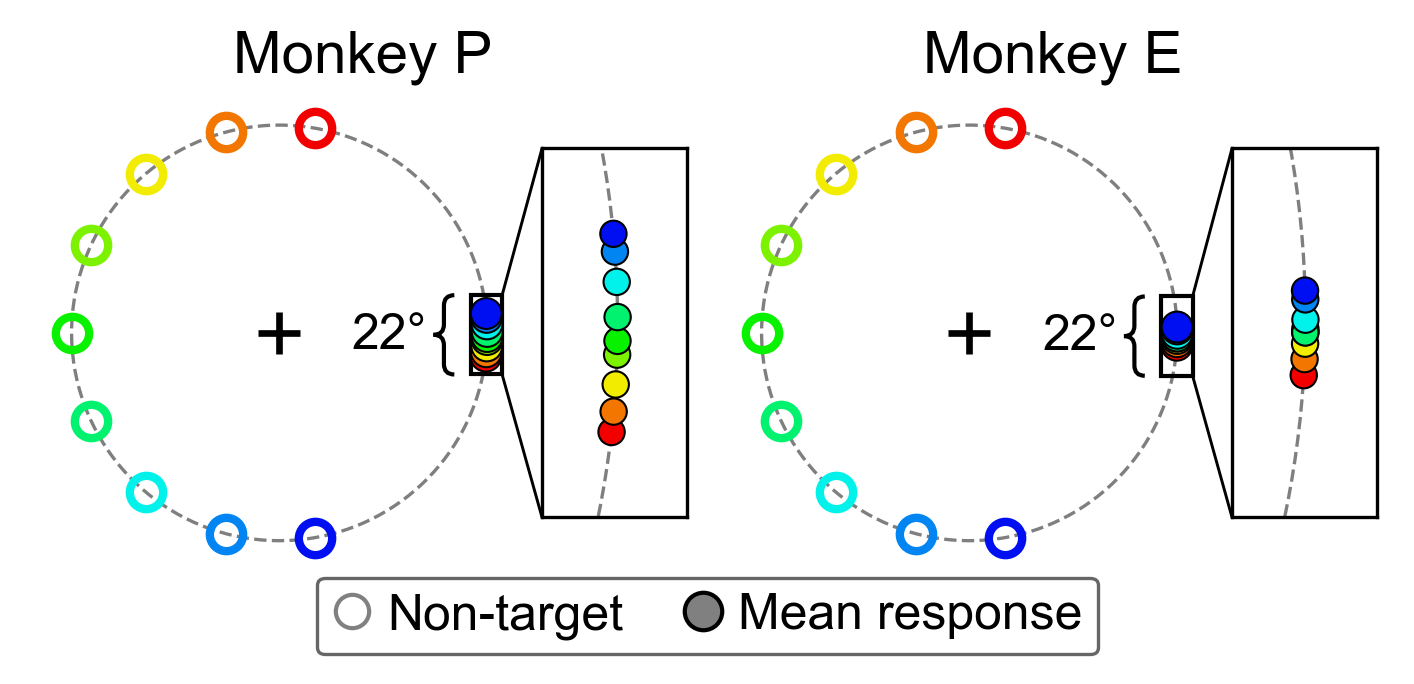

In [4]:
BOX_THETA = 22.0                                  # the box's height, as an angle at fixation
BOX_R = 0.15                                      # and its width, in ring radii
BOX_H = 2 * np.sin(np.radians(BOX_THETA) / 2)     # that angle as a chord on the ring
INSET_SCALE, INSET_X = 0.74, 0.77                 # the inset's height and left edge
XLIM, YLIM = (-1.2, 2.0), (-1.2, 1.2)             # room on the right for the inset

fig, axes = plt.subplots(1, len(common.SUBJECTS), figsize=FIGSIZE_RING, squeeze=False,
                         layout='constrained')
fig.get_layout_engine().set(rect=(0, 0.10, 1, 0.90), wspace=0.0)   # band for the legend

# Inset width (axes fraction) that renders the box at equal aspect.
inset_w = INSET_SCALE * (BOX_R / BOX_H) * ((YLIM[1] - YLIM[0]) / (XLIM[1] - XLIM[0]))
circle = np.linspace(0, 2 * np.pi, 300)

for ax, subject in zip(axes[0], common.SUBJECTS):
    trials = plotted[plotted['subject'] == subject]
    common.draw_ring(ax)

    dots = []
    for k, center in enumerate(BIN_CENTERS):
        errors = trials['error'].values[trials['bin'].values == k]
        if not len(errors):
            continue
        # The non-target's own position: an open circle, so the ring shows through it.
        a = np.radians(center)
        ax.plot(np.cos(a), np.sin(a), 'o', markerfacecolor='none',
                markeredgecolor=BIN_COLORS[k], markersize=8, markeredgewidth=2.0, zorder=5)
        mean_angle = np.arctan2(np.sin(errors).mean(), np.cos(errors).mean())
        dots.append((np.cos(mean_angle), np.sin(mean_angle), BIN_COLORS[k]))
    dot_x, dot_y, dot_c = map(np.array, zip(*dots))
    ax.scatter(dot_x, dot_y, s=55, color=dot_c, linewidths=0.5, edgecolors='k', zorder=6)

    ax.set_aspect('equal')
    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(common.SUBJECT_LABELS[subject], pad=0)

    # The box, centred on the cluster of mean-error dots.
    cx, cy = 0.5 * (dot_x.min() + dot_x.max()), 0.5 * (dot_y.min() + dot_y.max())
    x0, y0 = cx - BOX_R / 2, cy - BOX_H / 2
    ax.add_patch(Rectangle((x0, y0), BOX_R, BOX_H, fill=False, edgecolor='k', lw=1.0,
                           zorder=4))

    # The inset: an undistorted blow-up of exactly that box.
    inset = ax.inset_axes([INSET_X, (1 - INSET_SCALE) / 2, inset_w, INSET_SCALE])
    inset.plot(np.cos(circle), np.sin(circle), 'k--', lw=0.8, alpha=0.5)
    inset.scatter(dot_x, dot_y, s=40, color=dot_c, linewidths=0.5, edgecolors='k', zorder=6)
    inset.set_xlim(x0, x0 + BOX_R)
    inset.set_ylim(y0, y0 + BOX_H)
    inset.set_aspect('equal')
    inset.set_xticks([])
    inset.set_yticks([])

    # The brace, on the box rather than on the inset: it is the box that is drawn to the
    # ring's own scale, so it is the box whose height means 22 degrees.
    xb = x0 - 0.08
    ax.add_patch(PathPatch(curly_brace(xb, cy - BOX_H / 2, cy + BOX_H / 2, 0.10),
                           fill=False, edgecolor='k', lw=1.0, zorder=4))
    ax.text(xb - 0.13, cy, f'{BOX_THETA:g}°', ha='right', va='center', fontsize=12)

    # Tie the box's near corners to the inset's.
    for corner_xy, inset_xy in [((x0 + BOX_R, y0 + BOX_H), (0, 1)),
                                ((x0 + BOX_R, y0), (0, 0))]:
        ax.add_artist(ConnectionPatch(xyA=corner_xy, coordsA=ax.transData,
                                      xyB=inset_xy, coordsB=inset.transAxes,
                                      color='k', lw=0.7, zorder=3))

common.boxed_legend(fig,
                    [common.legend_dot('none', 8, edge='0.5'),
                     common.legend_dot('0.5', 9, edge='k')],
                    ['Non-target', 'Mean response'],
                    loc='lower center', bbox_to_anchor=(0.5, 0.0))
common.save(fig, OUTPUT_RING)
plt.show()

## The cloud

The same trials, unaggregated: every response error against its inter-object angle, jittered
within its bin so the dots do not stack, with the bin's mean ± SD in black.

saved repulsion_bias_cloud.pdf


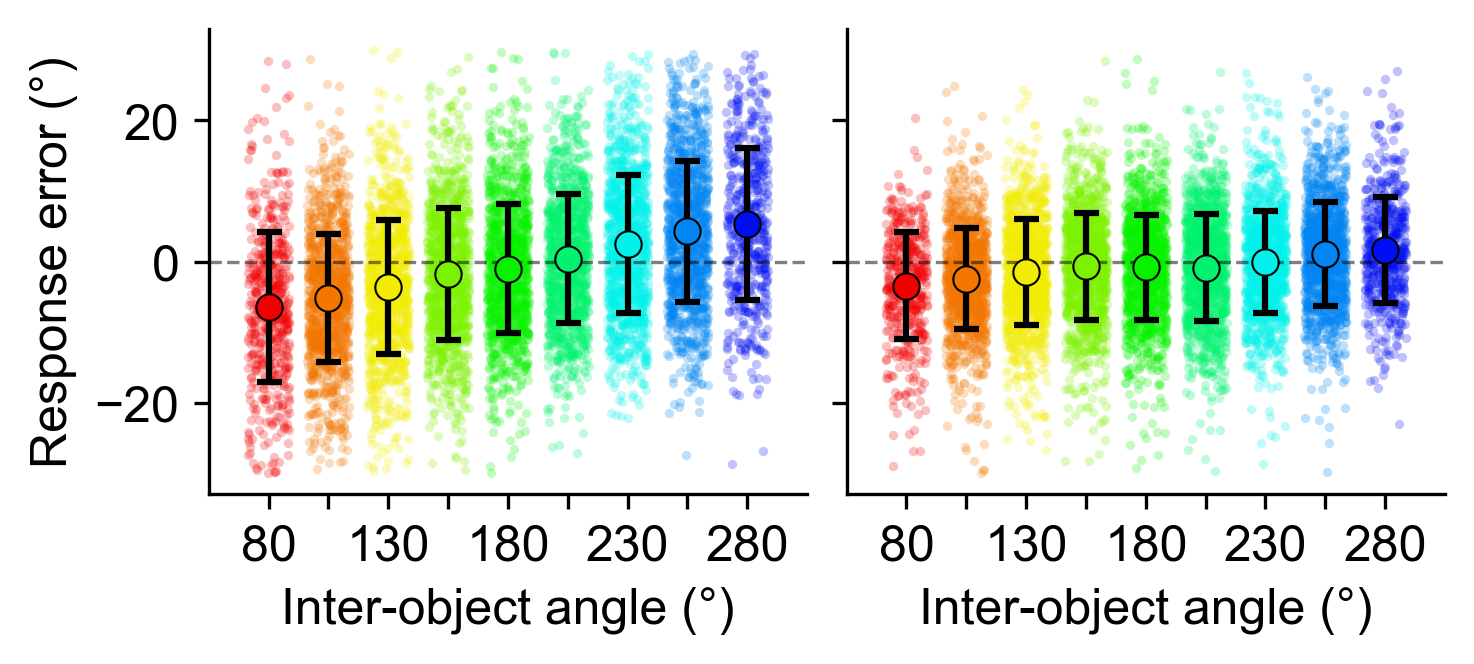

In [5]:
fig, axes = plt.subplots(1, len(common.SUBJECTS), figsize=FIGSIZE_CLOUD, sharey=True,
                         squeeze=False, layout='constrained')
rng = np.random.default_rng(0)

for ax, subject in zip(axes[0], common.SUBJECTS):
    trials = plotted[plotted['subject'] == subject]
    for k, center in enumerate(BIN_CENTERS):
        errors = trials['error_deg'].values[trials['bin'].values == k]
        if not len(errors):
            continue
        ax.scatter(center + rng.uniform(-8.75, 8.75, len(errors)), errors,
                   color=BIN_COLORS[k], s=5, alpha=0.25, linewidths=0, zorder=2)
        ax.errorbar(center, errors.mean(), yerr=errors.std(ddof=1), fmt='none', ecolor='k',
                    elinewidth=1.5, capsize=3, capthick=1.5, zorder=6)
        ax.scatter(center, errors.mean(), color=BIN_COLORS[k], s=40, edgecolors='k',
                   linewidths=0.5, zorder=7)

    ax.axhline(0, color='k', lw=0.8, alpha=0.5, linestyle='--')
    ax.set_xlim(BIN_CENTERS[0] - 25, BIN_CENTERS[-1] + 25)
    ax.set_xticks(BIN_CENTERS)
    ax.set_xticklabels([f'{c:.0f}' if c in LABELLED_TICKS else '' for c in BIN_CENTERS])
    ax.set_xlabel('Inter-object angle (°)')
    common.despine(ax)
axes[0, 0].set_ylabel('Response error (°)')

common.save(fig, OUTPUT_CLOUD)
plt.show()

## Variance explained

The fraction of the response-error variance predictable from the inter-object angle
(η² over the bins), for exactly the trials the figures plot. The ± is the SD of the estimate
over 1000 trial bootstraps.

In [6]:
rng = np.random.default_rng(0)
for subject in common.SUBJECTS:
    trials = plotted[plotted['subject'] == subject]
    errors, bins = trials['error_deg'].values, trials['bin'].values
    boot = [rs.eta_squared(errors[i], bins[i])
            for i in (rng.integers(0, len(errors), len(errors)) for _ in range(1000))]
    print(f'{common.SUBJECT_LABELS[subject]}: {100 * rs.eta_squared(errors, bins):.2f}% '
          f'+/- {100 * np.std(boot, ddof=1):.2f}%')

Monkey P: 11.77% +/- 0.65%
Monkey E: 2.80% +/- 0.32%


## Does the error actually depend on the inter-object angle?

Two tests, both in [`repulsion_stats.py`](repulsion_stats.py), on exactly the trials plotted
above.

**Directed** — is the response pushed *away* from the non-target? Each session is fit
`error = a + b · (−sin d)`, where `d` is the non-target's signed position relative to the
target, so **`b` is the repulsion amplitude in degrees**: the bias at a 90° separation,
positive when repelled. The intercept `a` is not optional — an animal with a constant
rotational bias would otherwise have it absorbed into `b` and be scored as repulsed, and
Monkey E has exactly such an offset.

**Omnibus** — does mean error differ across the nine bins at all, with no assumption about
shape? Statistic is the η² above; the null permutes bin labels **within session**.

The unit of replication is the **session**, not the trial. Trials within a session share an
animal, a day and a calibration, so treating ~9,000 of them as independent would give a
p-value of no meaning. `b` is fit once per session and tested across the 11–12 sessions.


In [7]:
N_PERM = 10000   # within-session shuffles behind the omnibus p; its floor is 1/(N_PERM + 1)

for subject in common.SUBJECTS:
    text, directed, omnibus = rs.report(plotted[plotted['subject'] == subject],
                                        common.SUBJECT_LABELS[subject], n_perm=N_PERM)
    print(text)
    print()


Monkey P: 9,193 trials, 11 sessions
   repulsion   b = +4.662° +/- 0.176 (SEM over sessions), 95% CI [+4.317, +5.008]
               t(10) = 26.47, p = 1.4e-10   (Wilcoxon p = 0.000977; 11/11 sessions positive)
   omnibus     eta^2 = 11.77%, permutation p = 1.0e-04 (10,000 within-session shuffles; null 95th pct 0.17%)

Monkey E: 9,640 trials, 12 sessions
   repulsion   b = +1.503° +/- 0.143 (SEM over sessions), 95% CI [+1.222, +1.783]
               t(11) = 10.49, p = 4.6e-07   (Wilcoxon p = 0.000488; 12/12 sessions positive)
   omnibus     eta^2 = 2.80%, permutation p = 1.0e-04 (10,000 within-session shuffles; null 95th pct 0.16%)

